# VGG16 Transfer Learning + Grad-CAM on Flower Photos

**Reid Sendroff**

I used an ImageNet-pretrained VGG16 for 5-class flower classification. In stage 1 I trained the classifier while the convolution layers were frozen. In stage 2 I fine-tuned the last convolution block. I then used Grad-CAM to check which image regions drove a prediction.

In [1]:
from pathlib import Path
import copy
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.models import vgg16, VGG16_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
STAGE1_EPOCHS = 5
STAGE2_EPOCHS = 5
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.9.1+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 5080


### Flower dataset

I used ImageNet normalization because VGG16 was pretrained on ImageNet. Training images were augmented, while validation and test images used only resizing, center cropping, and normalization.

In [2]:
flower_root = DATA_DIR / "flower_photos"
if not flower_root.exists():
    download_and_extract_archive(
        "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
        download_root=str(DATA_DIR),
    )
catalog = datasets.ImageFolder(flower_root)
class_names = catalog.classes
records = [(Path(path), label) for path, label in catalog.samples]
labels = [label for _, label in records]
train_records, remaining = train_test_split(
    records, test_size=0.30, random_state=SEED, stratify=labels
)
val_records, test_records = train_test_split(
    remaining,
    test_size=0.50,
    random_state=SEED,
    stratify=[label for _, label in remaining],
)

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class PhotoDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label = self.records[index]
        with Image.open(path) as image:
            return self.transform(image.convert("RGB")), label

train_dataset = PhotoDataset(train_records, train_transform)
val_dataset = PhotoDataset(val_records, eval_transform)
test_dataset = PhotoDataset(test_records, eval_transform)
loader_options = {"batch_size": BATCH_SIZE, "num_workers": 0, "pin_memory": device.type == "cuda"}
train_loader = DataLoader(
    train_dataset, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_options
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)
print("Class mapping:", catalog.class_to_idx)
print("Train/validation/test:", len(train_dataset), len(val_dataset), len(test_dataset))
images, labels_batch = next(iter(train_loader))
print("Batch shapes:", tuple(images.shape), tuple(labels_batch.shape))

Class mapping: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}
Train/validation/test: 2569 550 551


Batch shapes:

 (32, 3, 224, 224) (32,)


### VGG16 model

I replaced the original 1000-class output with five flower logits. The input batch has shape `[N,3,224,224]` and the output has shape `[N,5]`.

In [3]:
weights = VGG16_Weights.DEFAULT
model = vgg16(weights=weights)
# freeze convolution layers for stage 1
for parameter in model.features.parameters():
    parameter.requires_grad = False
model.classifier[6] = nn.Linear(model.classifier[6].in_features, len(class_names))
model = model.to(device)
criterion = nn.CrossEntropyLoss()

with torch.inference_mode():
    output = model(images[:2].to(device))
print("Output shape:", tuple(output.shape))
assert output.shape == (2, len(class_names))
print("Stage 1 trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Output shape: (2, 5)
Stage 1 trainable parameters: 119566341


In [4]:
def evaluate(model, loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    count = 0
    all_labels = []
    all_predictions = []
    with torch.inference_mode():
        for inputs, labels in loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(inputs)
            predictions = logits.argmax(dim=1)
            loss_sum += criterion(logits, labels).item() * labels.size(0)
            correct += (predictions == labels).sum().item()
            count += labels.size(0)
            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())
    macro_precision = precision_score(
        all_labels, all_predictions, average="macro", zero_division=0
    )
    return loss_sum / count, correct / count, macro_precision, count


def train_stage(model, optimizer, epochs, stage_name):
    best_val_loss = float("inf")
    best_state = None
    history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        correct = 0
        count = 0
        for inputs, labels in train_loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            count += labels.size(0)
        train_loss = loss_sum / count
        train_accuracy = correct / count
        val_loss, val_accuracy, _, _ = evaluate(model, val_loader)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"{stage_name} epoch {epoch:02d}/{epochs}: "
            f"train acc {train_accuracy:.1%}, val acc {val_accuracy:.1%}"
        )
    model.load_state_dict(best_state)
    print(f"{stage_name}: restored epoch {best_epoch} (lowest validation loss).")
    return history, best_epoch

### Stage 1

In [5]:
stage1_optimizer = torch.optim.Adam(
    (p for p in model.parameters() if p.requires_grad), lr=1e-3
)
start = time.perf_counter()
stage1_history, stage1_best_epoch = train_stage(
    model, stage1_optimizer, STAGE1_EPOCHS, "Stage 1"
)
stage1_test_loss, stage1_test_accuracy, stage1_test_precision, stage1_test_count = evaluate(model, test_loader)
print(
    f"Stage 1 entire test set ({stage1_test_count} images): "
    f"loss {stage1_test_loss:.4f}, accuracy {stage1_test_accuracy:.2%}, "
    f"macro precision {stage1_test_precision:.2%}"
)
print(f"Elapsed: {(time.perf_counter() - start) / 60:.1f} minutes")

Stage 1 epoch 01/5: train acc 70.2%, val acc 80.7%


Stage 1 epoch 02/5: train acc 83.1%, val acc 78.0%


Stage 1 epoch 03/5: train acc 84.5%, val acc 85.6%


Stage 1 epoch 04/5: train acc 87.2%, val acc 82.5%


Stage 1 epoch 05/5: train acc 89.5%, val acc 83.6%
Stage 1: restored epoch 3 (lowest validation loss).


Stage 1 entire test set (551 images): loss 0.5873, accuracy 87.66%, macro precision 88.20%
Elapsed: 1.0 minutes


### Stage 2

I unfroze the last VGG16 convolution block and used a smaller learning rate for fine-tuning.

In [6]:
# fine-tune the last convolution block
for parameter in model.features[24:].parameters():
    parameter.requires_grad = True
print("Stage 2 trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

stage2_optimizer = torch.optim.Adam(
    (p for p in model.parameters() if p.requires_grad), lr=1e-4
)
stage2_history, stage2_best_epoch = train_stage(
    model, stage2_optimizer, STAGE2_EPOCHS, "Stage 2"
)
stage2_test_loss, stage2_test_accuracy, stage2_test_precision, stage2_test_count = evaluate(model, test_loader)
print(
    f"Stage 2 entire test set ({stage2_test_count} images): "
    f"loss {stage2_test_loss:.4f}, accuracy {stage2_test_accuracy:.2%}, "
    f"macro precision {stage2_test_precision:.2%}"
)
print(
    f"Fine-tuning changed test accuracy from {stage1_test_accuracy:.2%} "
    f"to {stage2_test_accuracy:.2%}."
)

Stage 2 trainable parameters: 126645765


Stage 2 epoch 01/5: train acc 91.4%, val acc 87.8%


Stage 2 epoch 02/5: train acc 93.7%, val acc 86.7%


Stage 2 epoch 03/5: train acc 96.8%, val acc 86.5%


Stage 2 epoch 04/5: train acc 98.1%, val acc 88.4%


Stage 2 epoch 05/5: train acc 97.2%, val acc 91.3%
Stage 2: restored epoch 5 (lowest validation loss).


Stage 2 entire test set (551 images): loss 0.4349, accuracy 90.74%, macro precision 90.61%
Fine-tuning changed test accuracy from 87.66% to 90.74%.


### One test image from every class

I selected one held-out test image for each of the five flower classes and classified them with the stage 2 model.

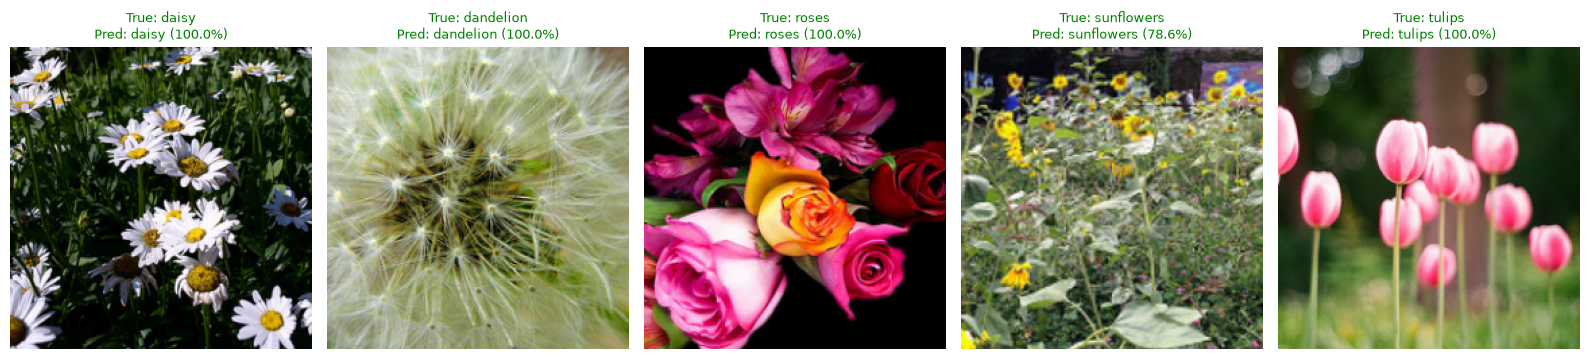

In [7]:
model.eval()
example_indices = []
for class_index in range(len(class_names)):
    example_indices.append(next(
        index for index, (_, label) in enumerate(test_records) if label == class_index
    ))

fig, axes = plt.subplots(1, len(class_names), figsize=(16, 4))
for axis, index in zip(axes, example_indices):
    tensor, actual = test_dataset[index]
    with torch.inference_mode():
        probabilities = model(tensor.unsqueeze(0).to(device)).softmax(dim=1)[0].cpu()
    predicted = probabilities.argmax().item()
    image = tensor.permute(1, 2, 0) * torch.tensor(std) + torch.tensor(mean)
    axis.imshow(image.clamp(0, 1))
    axis.set_title(
        f"True: {class_names[actual]}\nPred: {class_names[predicted]} "
        f"({probabilities[predicted]:.1%})",
        color="green" if predicted == actual else "red",
        fontsize=9,
    )
    axis.axis("off")
plt.tight_layout()
plt.show()

### Results

Stage 1 used all 551 test images and reached 87.66% accuracy and 88.20% macro precision. Stage 2 reached 90.74% accuracy and 90.61% macro precision. Fine-tuning improved accuracy by 3.08 percentage points.

The stage 2 model correctly classified the five displayed test images, one from every flower class.

## Grad-CAM

I used Grad-CAM on a flower image from the stage 2 model. Grad-CAM uses the gradient of the predicted class score with respect to the final convolution feature maps. Red areas in the overlay had the largest effect on the prediction.

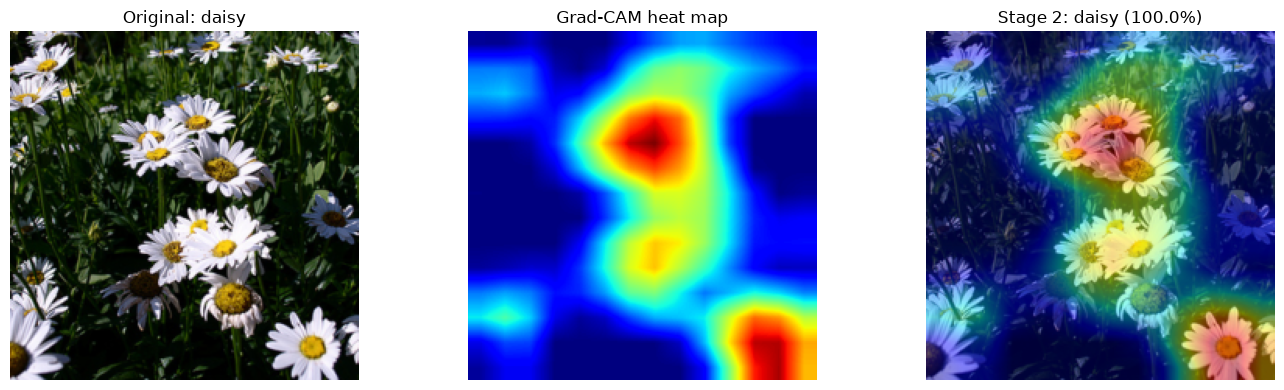

Grad-CAM target layer: Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


In [8]:
def grad_cam(model, image_tensor, target_layer, class_index=None):
    saved = {}

    def forward_hook(module, inputs, output):
        saved["activations"] = output
        output.register_hook(lambda gradient: saved.__setitem__("gradients", gradient))

    handle = target_layer.register_forward_hook(forward_hook)
    model.eval()
    model.zero_grad(set_to_none=True)
    logits = model(image_tensor.unsqueeze(0).to(device))
    if class_index is None:
        class_index = logits.argmax(dim=1).item()
    logits[0, class_index].backward()
    handle.remove()

    activations = saved["activations"].detach()
    gradients = saved["gradients"].detach()
    channel_weights = gradients.mean(dim=(2, 3), keepdim=True)
    heatmap = torch.relu((channel_weights * activations).sum(dim=1, keepdim=True))
    heatmap = torch.nn.functional.interpolate(
        heatmap, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False
    )[0, 0]
    heatmap -= heatmap.min()
    heatmap /= heatmap.max().clamp_min(1e-8)
    return heatmap.cpu(), class_index, logits.softmax(dim=1)[0, class_index].item()


gradcam_index = next(
    index for index, (_, label) in enumerate(test_records) if label == 0
)
gradcam_tensor, gradcam_actual = test_dataset[gradcam_index]
heatmap, gradcam_prediction, gradcam_probability = grad_cam(
    model, gradcam_tensor, model.features[28]
)
display_image = gradcam_tensor.permute(1, 2, 0) * torch.tensor(std) + torch.tensor(mean)
display_image = display_image.clamp(0, 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(display_image)
axes[0].set_title(f"Original: {class_names[gradcam_actual]}")
axes[1].imshow(heatmap, cmap="jet")
axes[1].set_title("Grad-CAM heat map")
axes[2].imshow(display_image)
axes[2].imshow(heatmap, cmap="jet", alpha=0.45)
axes[2].set_title(
    f"Stage 2: {class_names[gradcam_prediction]} ({gradcam_probability:.1%})"
)
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()
assert heatmap.shape == (IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(heatmap).all()
print("Grad-CAM target layer:", model.features[28])

### Grad-CAM result

The stage 2 model predicted the image as a daisy. The strongest Grad-CAM regions were mainly on the central daisy blossoms instead of the dark background.